# Predictive Maintenance of Turbofan Engines using Machine Learning Classification
## Notebook 1 — Data Understanding

**Goal of this notebook:** load the NASA C-MAPSS FD001 data, give every column a name, and understand what one row means — before doing any analysis.

### The problem (in one line)
Given an engine's sensor readings, predict **whether it will fail within the next 30 cycles** (yes / no).

### What is predictive maintenance?
| Strategy | When you repair | Problem |
|---|---|---|
| Reactive | After it breaks | Unplanned downtime, can be dangerous |
| Preventive | On a fixed schedule | Replaces healthy parts too early → wasted money |
| **Predictive** | **When the data says failure is near** | Needs data + a model → **this project** |

## 1. About the dataset

**Source:** NASA Ames Prognostics Center of Excellence — *C-MAPSS* (Commercial Modular Aero-Propulsion System Simulation).
Reference: A. Saxena, K. Goebel, D. Simon, N. Eklund, *"Damage Propagation Modeling for Aircraft Engine Run-to-Failure Simulation"*, PHM 2008.
Download: https://data.nasa.gov/dataset/cmapss-jet-engine-simulated-data (U.S. Government work, public).

**What it is:** a high-fidelity NASA simulation of a fleet of turbofan (jet) engines. Each engine starts healthy, with some random initial wear, and is run **until it fails**.

C-MAPSS has 4 subsets. **We use only FD001** — the simplest one:

| Subset | Train engines | Test engines | Operating conditions | Fault modes |
|---|---|---|---|---|
| **FD001** | **100** | **100** | **1** (sea level) | **1** (HPC degradation) |
| FD002 | 260 | 259 | 6 | 1 |
| FD003 | 100 | 100 | 1 | 2 |
| FD004 | 248 | 249 | 6 | 2 |

*HPC = High-Pressure Compressor.* One condition + one fault mode means any change in the sensors is due to wear, not due to flying conditions — easier to model and to explain.

**The 3 files we use:**
| File | What it contains |
|---|---|
| `train_FD001.txt` | Full life of 100 engines — every engine runs **until failure** |
| `test_FD001.txt` | 100 *other* engines — data **stops some time before failure** |
| `RUL_FD001.txt` | The true number of cycles each test engine had left when its data stopped (the "answer key") |

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 30)

# Folder that holds train_FD001.txt, test_FD001.txt, RUL_FD001.txt
# (on Google Colab: upload the 3 files and set DATA_DIR = ".")
DATA_DIR = "../data/raw/CMAPSSData"

## 2. Naming the columns

The raw files have **no header** — just 26 numbers per row separated by spaces. From the dataset readme and the Saxena et al. paper, the columns are:

- **unit** — engine ID (1 to 100)
- **cycle** — time step; one cycle ≈ one flight
- **setting_1, setting_2, setting_3** — operational settings (altitude, Mach number, throttle). In FD001 these barely change (one operating condition).
- **s1 … s21** — 21 sensor measurements

| Sensor | Symbol | Meaning | Unit |
|---|---|---|---|
| s1 | T2 | Total temperature at fan inlet | °R |
| s2 | T24 | Total temperature at LPC outlet | °R |
| s3 | T30 | Total temperature at HPC outlet | °R |
| s4 | T50 | Total temperature at LPT outlet | °R |
| s5 | P2 | Pressure at fan inlet | psia |
| s6 | P15 | Total pressure in bypass duct | psia |
| s7 | P30 | Total pressure at HPC outlet | psia |
| s8 | Nf | Physical fan speed | rpm |
| s9 | Nc | Physical core speed | rpm |
| s10 | epr | Engine pressure ratio (P50/P2) | – |
| s11 | Ps30 | Static pressure at HPC outlet | psia |
| s12 | phi | Ratio of fuel flow to Ps30 | pps/psi |
| s13 | NRf | Corrected fan speed | rpm |
| s14 | NRc | Corrected core speed | rpm |
| s15 | BPR | Bypass ratio | – |
| s16 | farB | Burner fuel-air ratio | – |
| s17 | htBleed | Bleed enthalpy | – |
| s18 | Nf_dmd | Demanded fan speed | rpm |
| s19 | PCNfR_dmd | Demanded corrected fan speed | rpm |
| s20 | W31 | HPT coolant bleed | lbm/s |
| s21 | W32 | LPT coolant bleed | lbm/s |

*LPC/HPC = Low/High-Pressure Compressor, LPT/HPT = Low/High-Pressure Turbine, °R = degrees Rankine.*

In [2]:
index_cols   = ["unit", "cycle"]
setting_cols = ["setting_1", "setting_2", "setting_3"]
sensor_cols  = [f"s{i}" for i in range(1, 22)]
col_names    = index_cols + setting_cols + sensor_cols

# sep=r"\s+" : columns are separated by one or more spaces
train = pd.read_csv(f"{DATA_DIR}/train_FD001.txt", sep=r"\s+", header=None, names=col_names)
test  = pd.read_csv(f"{DATA_DIR}/test_FD001.txt",  sep=r"\s+", header=None, names=col_names)
rul   = pd.read_csv(f"{DATA_DIR}/RUL_FD001.txt",   sep=r"\s+", header=None, names=["true_RUL"])

print("train:", train.shape, "| test:", test.shape, "| RUL:", rul.shape)

train: (20631, 26) | test: (13096, 26) | RUL: (100, 1)


## 3. What does one row mean?

**One row = one engine at one cycle.** It is a snapshot: *"engine 1, after flight number 1, had these 3 settings and these 21 sensor readings."*

So the data is a **time series per engine**: engine 1 has rows for cycle 1, 2, 3, … until it fails.

In [3]:
train.head()

,unit,cycle,setting_1,setting_2,setting_3,s1,s2,s3,s4,s5,s6,s7,s8,s9,s10,s11,s12,s13,s14,s15,s16,s17,s18,s19,s20,s21
0,1,1,-0.0007,-0.0004,100.0,518.67,641.82,1589.70,1400.60,14.62,21.61,554.36,2388.06,9046.19,1.3,47.47,521.66,2388.02,8138.62,8.4195,0.03,392,2388,100.0,39.06,23.4190
1,1,2,0.0019,-0.0003,100.0,518.67,642.15,1591.82,1403.14,14.62,21.61,553.75,2388.04,9044.07,1.3,47.49,522.28,2388.07,8131.49,8.4318,0.03,392,2388,100.0,39.00,23.4236
2,1,3,-0.0043,0.0003,100.0,518.67,642.35,1587.99,1404.20,14.62,21.61,554.26,2388.08,9052.94,1.3,47.27,522.42,2388.03,8133.23,8.4178,0.03,390,2388,100.0,38.95,23.3442
3,1,4,0.0007,0.0000,100.0,518.67,642.35,1582.79,1401.87,14.62,21.61,554.45,2388.11,9049.48,1.3,47.13,522.86,2388.08,8133.83,8.3682,0.03,392,2388,100.0,38.88,23.3739
4,1,5,-0.0019,-0.0002,100.0,518.67,642.37,1582.85,1406.22,14.62,21.61,554.00,2388.06,9055.15,1.3,47.28,522.19,2388.04,8133.80,8.4294,0.03,393,2388,100.0,38.90,23.4044


In [4]:
# The full life of engine 1: cycles 1 ... last cycle (= the cycle it failed)
engine_1 = train[train["unit"] == 1]
print(f"Engine 1 has {len(engine_1)} rows -> it failed after cycle {engine_1['cycle'].max()}")
engine_1[["unit", "cycle", "s2", "s3", "s4", "s7", "s11"]].tail()

Engine 1 has 192 rows -> it failed after cycle 192


,unit,cycle,s2,s3,s4,s7,s11
187,1,188,643.75,1602.38,1422.78,551.94,48.00
188,1,189,644.18,1596.17,1428.01,550.70,48.08
189,1,190,643.64,1599.22,1425.95,551.29,48.33
190,1,191,643.34,1602.36,1425.77,550.92,48.15
191,1,192,643.54,1601.41,1427.20,551.25,48.25


## 4. Basic data-quality checks

Before any analysis we check: data types, missing values, duplicate rows, and that every engine's cycles run 1, 2, 3, … without gaps.

In [5]:
train.info()

<class 'pandas.DataFrame'>
RangeIndex: 20631 entries, 0 to 20630
Data columns (total 26 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   unit       20631 non-null  int64  
 1   cycle      20631 non-null  int64  
 2   setting_1  20631 non-null  float64
 3   setting_2  20631 non-null  float64
 4   setting_3  20631 non-null  float64
 5   s1         20631 non-null  float64
 6   s2         20631 non-null  float64
 7   s3         20631 non-null  float64
 8   s4         20631 non-null  float64
 9   s5         20631 non-null  float64
 10  s6         20631 non-null  float64
 11  s7         20631 non-null  float64
 12  s8         20631 non-null  float64
 13  s9         20631 non-null  float64
 14  s10        20631 non-null  float64
 15  s11        20631 non-null  float64
 16  s12        20631 non-null  float64
 17  s13        20631 non-null  float64
 18  s14        20631 non-null  float64
 19  s15        20631 non-null  float64
 20  s16        20631 

In [6]:
print("Missing values (train):", train.isna().sum().sum())
print("Missing values (test): ", test.isna().sum().sum())
print("Duplicate rows (train):", train.duplicated().sum())

# Every engine should have cycles 1..N with no gaps
gaps = train.groupby("unit")["cycle"].apply(lambda c: (c.diff().dropna() != 1).sum()).sum()
print("Cycle gaps (train):    ", gaps)

Missing values (train): 0
Missing values (test):  0
Duplicate rows (train): 0
Cycle gaps (train):     0


In [7]:
train.describe().T

,count,mean,std,min,25%,50%,75%,max
unit,20631.0,51.506568,2.922763e+01,1.0000,26.0000,52.0000,77.0000,100.0000
cycle,20631.0,108.807862,6.888099e+01,1.0000,52.0000,104.0000,156.0000,362.0000
setting_1,20631.0,-0.000009,2.187313e-03,-0.0087,-0.0015,0.0000,0.0015,0.0087
setting_2,20631.0,0.000002,2.930621e-04,-0.0006,-0.0002,0.0000,0.0003,0.0006
setting_3,20631.0,100.000000,0.000000e+00,100.0000,100.0000,100.0000,100.0000,100.0000
s1,20631.0,518.670000,0.000000e+00,518.6700,518.6700,518.6700,518.6700,518.6700
s2,20631.0,642.680934,5.000533e-01,641.2100,642.3250,642.6400,643.0000,644.5300
s3,20631.0,1590.523119,6.131150e+00,1571.0400,1586.2600,1590.1000,1594.3800,1616.9100
s4,20631.0,1408.933782,9.000605e+00,1382.2500,1402.3600,1408.0400,1414.5550,1441.4900
s5,20631.0,14.620000,5.329200e-15,14.6200,14.6200,14.6200,14.6200,14.6200


**What to look for in the table above:** columns whose `std` is 0 (or almost 0) **never change** — they carry no information about wear. We will confirm and drop them in Notebook 2 (EDA).

In [8]:
# Quick preview: how many distinct values does each column have?
nunique = train[setting_cols + sensor_cols].nunique().sort_values()
nunique.head(10)

s1            1
setting_3     1
s5            1
s10           1
s18           1
s19           1
s16           1
s6            2
s17          13
setting_2    13
dtype: int64

## 5. How long do engines live?

In the training set every engine runs until failure, so **an engine's lifetime = its last cycle number**.

count    100.0
mean     206.3
std       46.3
min      128.0
25%      177.0
50%      199.0
75%      229.2
max      362.0
Name: cycle, dtype: float64


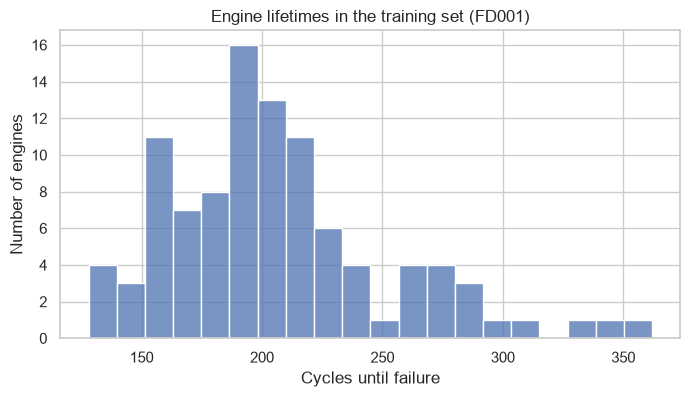

In [9]:
lifetimes = train.groupby("unit")["cycle"].max()
print(lifetimes.describe().round(1))

plt.figure(figsize=(8, 4))
sns.histplot(lifetimes, bins=20)
plt.title("Engine lifetimes in the training set (FD001)")
plt.xlabel("Cycles until failure")
plt.ylabel("Number of engines")
plt.show()

**Interpretation:** engines do **not** all fail at the same age. If they did, a simple fixed schedule ("service every N cycles") would be enough. Because lifetimes vary a lot, we need the **sensor data** to tell *this particular* engine's condition — which is exactly why predictive maintenance is useful.

## 6. How is the test set different?

- **Train:** each engine runs **until failure** → we know exactly how many cycles were left at every row.
- **Test:** each engine's data **stops early**, at some random point before failure. `RUL_FD001.txt` tells us how many cycles it really had left at that last row.

**RUL = Remaining Useful Life** = number of cycles left before failure.

In [10]:
test_last = test.groupby("unit")["cycle"].max().rename("last_cycle_seen").to_frame()
test_last["true_RUL"] = rul["true_RUL"].values          # row i of RUL file = engine i
test_last["total_life"] = test_last["last_cycle_seen"] + test_last["true_RUL"]
test_last.head()

,last_cycle_seen,true_RUL,total_life
unit,,,
1,31,112,143
2,49,98,147
3,126,69,195
4,106,82,188
5,98,91,189


In [11]:
print("Test engines:", test["unit"].nunique())
print("Test engines that were within 30 cycles of failure when data stopped:",
      (test_last["true_RUL"] <= 30).sum())

Test engines: 100
Test engines that were within 30 cycles of failure when data stopped: 25


## 7. Preview: how the label will be built (done properly in Notebook 3)

For every training row:

$$\text{RUL} = \text{last cycle of that engine} - \text{current cycle}$$

$$\text{label} = \begin{cases} 1 & \text{if RUL} \le 30 \;\; (\text{will fail soon}) \\ 0 & \text{otherwise} \end{cases}$$

Below is a quick preview only, to see roughly how balanced the two classes will be.

In [12]:
preview_rul = train.groupby("unit")["cycle"].transform("max") - train["cycle"]
preview_label = (preview_rul <= 30).astype(int)
print(preview_label.value_counts().rename({0: "0 = healthy", 1: "1 = fails within 30 cycles"}))
print(f"\nShare of 'fails soon' rows: {preview_label.mean():.1%}")

cycle
0 = healthy                   17531
1 = fails within 30 cycles     3100
Name: count, dtype: int64

Share of 'fails soon' rows: 15.0%


**Interpretation:** only a minority of rows are "fails soon" → the classes are **imbalanced**. This is why, later, **accuracy alone will be misleading** and we will focus on **recall, precision and F1**.

## 8. Key takeaways (Notebook 1)

1. FD001 = 100 training engines run to failure + 100 test engines cut off early, with an answer key (`RUL_FD001.txt`).
2. One row = one engine at one cycle → each engine is a **time series**.
3. 26 columns: engine ID, cycle, 3 settings, 21 sensors. The data is clean: no missing values, no duplicates, no gaps.
4. Some columns barely or never change → candidates to drop (Notebook 2).
5. Engine lifetimes vary a lot → a fixed maintenance schedule would not work well; sensor data is needed.
6. The yes/no label will be imbalanced → choose metrics carefully.

## Likely viva questions on this part
- *What is one row of your data?* → One engine at one cycle (≈ one flight).
- *Why FD001 and not the other subsets?* → One operating condition and one fault mode, so sensor changes reflect wear only; simplest to model and explain.
- *How is the test set different from the training set?* → Test engines stop before failure; the true remaining life is given separately in `RUL_FD001.txt`.
- *Is the data real?* → It is a high-fidelity NASA simulation, the standard benchmark for predictive maintenance research.
- *What is RUL?* → Remaining Useful Life: cycles left before failure.

**Next → Notebook 2: Exploratory Data Analysis.**